# Customer Segmentation with RFM and Clustering

CSC 3730, Fall 2026, Group 6: Hammaad Alam, Nick Jaramillo, Fahd Khattak, Damien Nguyen, Madison Nguyen, Taylor Wall, Demetri Williams

The goal of this project is to group the customers of an online retailer by how they buy, so that marketing can treat different kinds of customers differently. There are no labels in the data, so this is an unsupervised learning problem. We build Recency, Frequency, and Monetary (RFM) features for each customer, cluster them with K-means, and compare the result with agglomerative clustering to see if a second method finds the same groups.

The data is the Online Retail dataset from the UCI Machine Learning Repository (Chen, 2015). It has 541,909 invoice lines from a UK online gift shop between December 2010 and December 2011. The dataset page says many of the customers are wholesalers.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Every figure is also saved to figures/ so it can be reused in the report and slides
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Preprocessing

RFM needs purchases that belong to a known customer, so we remove rows with no CustomerID, cancellations, and rows with a zero or negative quantity or price. `original_df` is kept unchanged so we can compare against the raw data.

In [2]:
# Load the dataset and preserve original_df
original_df = pd.read_excel("Online Retail.xlsx")
print("Shape:", original_df.shape)

Shape: (541909, 8)


In [3]:
# Display the first few rows of the dataset
original_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# Summarize numeric columns and transaction dates
original_df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [5]:
# Inspect column types and non-null counts
original_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [6]:
# Count missing values and exact duplicates, duplicates are assessed after cleaning
display(original_df.isna().sum())
print("Number of duplicate rows:", original_df.duplicated().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Number of duplicate rows: 5268


About a quarter of the rows have no CustomerID. We can't tell who made those purchases, so they can't be used for customer-level features and we drop them.

In [7]:
# Keep transactions with a known CustomerID for customer-level analysis
customer_df = original_df.dropna(subset=['CustomerID'])
print("New Shape:", customer_df.shape)

New Shape: (406829, 8)


Invoices that start with C are cancellations. We drop those rows but keep the original purchase rows, so Monetary is what the customer ordered, not what they kept after returns.

In [8]:
# Identify cancellation rows among transactions with a known CustomerID
canceled_transactions = customer_df[customer_df["InvoiceNo"].astype(str).str.startswith("C")]

print("Canceled rows:", len(canceled_transactions))
print("Unique canceled invoices:", canceled_transactions["InvoiceNo"].nunique())
print("Customers with cancellations:", canceled_transactions["CustomerID"].nunique())

Canceled rows: 8905
Unique canceled invoices: 3654
Customers with cancellations: 1589


In [9]:
# Exclude cancellation rows, original purchases remain in the data
non_canceled_df = customer_df[~customer_df["InvoiceNo"].astype(str).str.startswith("C")]
non_canceled_df.shape

(397924, 8)

In [10]:
# Select rows with zero or negative quantities or prices for analysis
non_positive_rows = non_canceled_df[(non_canceled_df["Quantity"] <= 0) | (non_canceled_df["UnitPrice"] <= 0)]
print("Rows with zero or negative quantity or price:", len(non_positive_rows))

Rows with zero or negative quantity or price: 40


In [11]:
# Keep positive quantities and prices, then copy for further preprocessing
positive_sales_df = non_canceled_df[(non_canceled_df["Quantity"] > 0) & (non_canceled_df["UnitPrice"] > 0)]
cleaned_df = positive_sales_df.copy()

In [12]:
# Calculate spending per line item before refunds and cancellations
cleaned_df["TotalPrice"] = cleaned_df["Quantity"] * cleaned_df["UnitPrice"]

In [13]:
# Report cleaned purchase rows, total rows removed, and unique customers
print("\nCleaned rows:", len(cleaned_df))
print("Rows removed:", len(original_df) - len(cleaned_df))
print("Unique customers:", cleaned_df["CustomerID"].nunique())


Cleaned rows: 397884
Rows removed: 144025
Unique customers: 4338


In [14]:
# Rows remaining after each cleaning step
cleaning_steps = pd.DataFrame(
    {"Rows": [len(original_df), len(customer_df), len(non_canceled_df), len(cleaned_df)]},
    index=["Raw data", "Known CustomerID", "Cancellations removed", "Positive quantity and price"],
)
cleaning_steps["PctOfRaw"] = cleaning_steps["Rows"] / len(original_df) * 100
display(cleaning_steps.round(1))

# Exact duplicate rows still in the cleaned data and how much spending they account for
duplicate_rows = cleaned_df[cleaned_df.duplicated()]
print("Exact duplicate rows in cleaned data:", len(duplicate_rows))
print(f"Share of cleaned rows: {len(duplicate_rows) / len(cleaned_df):.2%}")
print(f"Share of total spending: {duplicate_rows['TotalPrice'].sum() / cleaned_df['TotalPrice'].sum():.2%}")

,Rows,PctOfRaw
Raw data,541909,100.0
Known CustomerID,406829,75.1
Cancellations removed,397924,73.4
Positive quantity and price,397884,73.4


Exact duplicate rows in cleaned data: 5192
Share of cleaned rows: 1.30%
Share of total spending: 0.27%


There are still about 5,200 exact duplicate rows (1.3% of rows, 0.27% of spending). We can't tell if these are data errors or the same item entered twice on an order, so we keep them. They don't affect Recency or Frequency, and the effect on Monetary is tiny.

In [15]:
display(cleaned_df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## Basic exploratory data analysis

,Sales,Orders
InvoiceDate,,
2010-12,572713.890,1400
2011-01,569445.040,987
2011-02,447137.350,997
2011-03,595500.760,1321
2011-04,469200.361,1149
2011-05,678594.560,1555
2011-06,661213.690,1393
2011-07,600091.011,1331
2011-08,645343.900,1280


Observed date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


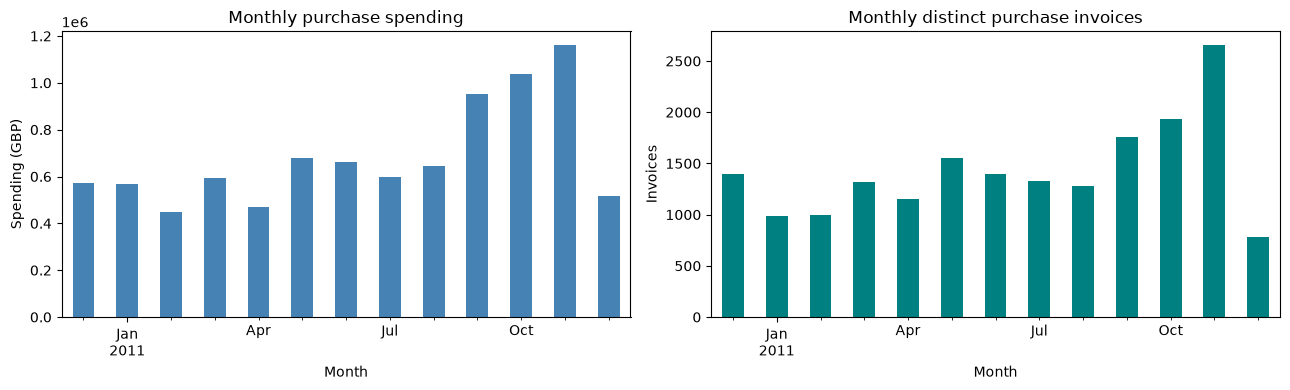

In [16]:
# Summarize monthly purchase spending and distinct orders
monthly_sales = cleaned_df.groupby(
    cleaned_df["InvoiceDate"].dt.to_period("M")
).agg(
    Sales=("TotalPrice", "sum"),
    Orders=("InvoiceNo", "nunique"),
)

display(monthly_sales)

print(
    "Observed date range:",
    cleaned_df["InvoiceDate"].min(),
    "to",
    cleaned_df["InvoiceDate"].max(),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

monthly_sales["Sales"].plot.bar(
    ax=axes[0], color="steelblue",
    title="Monthly purchase spending",
)

monthly_sales["Orders"].plot.bar(
    ax=axes[1], color="teal",
    title="Monthly distinct purchase invoices",
)

axes[0].set_ylabel("Spending (GBP)")
axes[1].set_ylabel("Invoices")

for ax in axes:
    ax.set_xlabel("Month")

plt.tight_layout()
save_fig("monthly_sales")
plt.show()

,Sales,Customers,SalesSharePct
Country,,,
United Kingdom,7308391.554,3920,82.011638
Netherlands,285446.340,9,3.203156
EIRE,265545.900,3,2.979842
Germany,228867.140,94,2.568249
France,209024.050,87,2.345578
Australia,138521.310,9,1.554427
Spain,61577.110,30,0.690992
Switzerland,56443.950,21,0.633390
Belgium,41196.340,25,0.462288


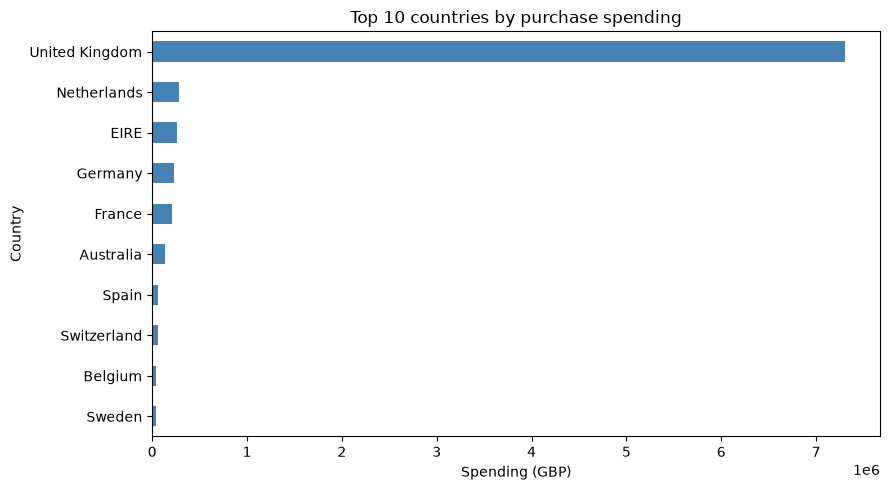

In [17]:
# Spending and share by country
country_sales = (
    cleaned_df.groupby("Country")
    .agg(Sales=("TotalPrice", "sum"), Customers=("CustomerID", "nunique"))
    .sort_values("Sales", ascending=False)
)
country_sales["SalesSharePct"] = country_sales["Sales"] / country_sales["Sales"].sum() * 100

display(country_sales)

top10 = country_sales.head(10).sort_values("Sales")
top10["Sales"].plot.barh(figsize=(9, 5), color="steelblue")

plt.title("Top 10 countries by purchase spending")
plt.xlabel("Spending (GBP)")
plt.ylabel("Country")
plt.tight_layout()
save_fig("top_countries")
plt.show()

,Orders,Spending,AverageOrderValue
count,4338.000000,4338.000000,4338.000000
mean,4.272015,2054.266460,419.166289
std,7.697998,8989.230441,1796.537944
min,1.000000,3.750000,3.450000
50%,2.000000,674.485000,293.900000
90%,9.000000,3646.531000,667.243070
99%,30.000000,19880.995700,2031.161200
max,209.000000,280206.020000,84236.250000


Customers with one purchase invoice: 34.4%


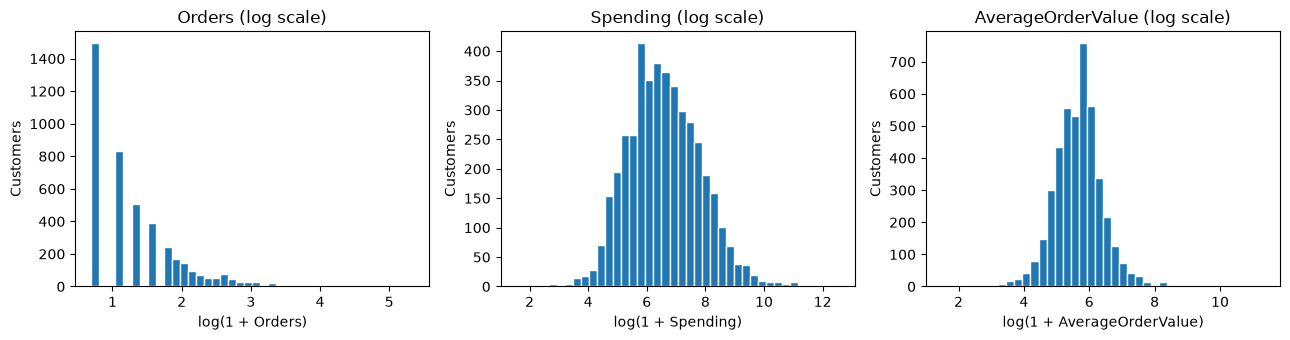

,InvoiceNo,CustomerID,InvoiceDate,Quantity,UnitPrice,TotalPrice
540421,581483,16446.0,2011-12-09 09:15:00,80995,2.08,168469.60
61619,541431,12346.0,2011-01-18 10:01:00,74215,1.04,77183.60
222680,556444,15098.0,2011-06-10 15:28:00,60,649.50,38970.00
173382,551697,16029.0,2011-05-03 13:46:00,1,8142.75,8142.75
348325,567423,17450.0,2011-09-20 11:05:00,1412,5.06,7144.72
52711,540815,15749.0,2011-01-11 12:55:00,3114,2.10,6539.40
160546,550461,15749.0,2011-04-18 13:20:00,3114,2.10,6539.40
421601,573003,14646.0,2011-10-27 12:11:00,2400,2.08,4992.00
52709,540815,15749.0,2011-01-11 12:55:00,1930,2.55,4921.50
160542,550461,15749.0,2011-04-18 13:20:00,1930,2.40,4632.00


In [18]:
# Summarize purchasing behavior by customer
customer_patterns = cleaned_df.groupby("CustomerID").agg(
    Orders=("InvoiceNo", "nunique"),
    Spending=("TotalPrice", "sum"),
)
customer_patterns["AverageOrderValue"] = (
    customer_patterns["Spending"] / customer_patterns["Orders"]
)

display(customer_patterns.describe(percentiles=[0.5, 0.9, 0.99]))
print(f"Customers with one purchase invoice: {(customer_patterns['Orders'] == 1).mean():.1%}")

# View the distributions on log scales
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes, ["Orders", "Spending", "AverageOrderValue"]):
    ax.hist(np.log1p(customer_patterns[column]), bins=40, edgecolor="white")
    ax.set(title=f"{column} (log scale)", xlabel=f"log(1 + {column})", ylabel="Customers")

plt.tight_layout()
save_fig("customer_distributions")
plt.show()

# Inspect the largest individual purchases
display(
    cleaned_df.nlargest(
        10, "TotalPrice"
    )[["InvoiceNo", "CustomerID", "InvoiceDate", "Quantity", "UnitPrice", "TotalPrice"]]
)

Things we noticed:

- Sales are fairly flat until August, then rise from September to a peak in November. December 2011 is low because the data stops on December 9.
- The UK makes up 82% of spending and about 90% of customers.
- Most customers are small (median 2 orders and about 675 GBP, and 34% ordered only once), but a few spend far more. Since orders and spending are so skewed, we log-transform before clustering.

## Customer-level RFM features

- Recency: days since the customer's last purchase, counted from the day after the last invoice in the data
- Frequency: number of different invoices
- Monetary: total spending in GBP

In [19]:
# Build customer-level RFM features for segmentation
snapshot_date = cleaned_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm_df = cleaned_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda d: (snapshot_date - d.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
).reset_index()

print("RFM shape:", rfm_df.shape)
rfm_df.describe()

RFM shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2054.266460
std,1721.808492,100.014169,7.697998,8989.230441
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,307.415000
50%,15299.500000,51.000000,2.000000,674.485000
75%,16778.750000,142.000000,5.000000,1661.740000
max,18287.000000,374.000000,209.000000,280206.020000


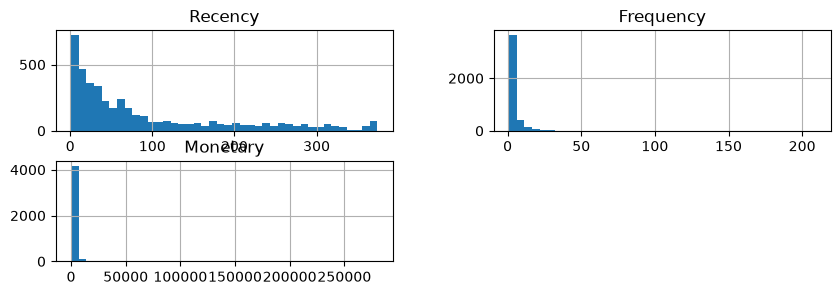

,Raw,Log
Recency,1.25,-0.38
Frequency,12.07,1.21
Monetary,19.32,0.39


In [20]:
# Check skew, then log-transform and standardize for clustering
from sklearn.preprocessing import StandardScaler

rfm_features = ["Recency", "Frequency", "Monetary"]

rfm_df[rfm_features].hist(bins=40, figsize=(10, 3))
save_fig("rfm_raw_histograms")
plt.show()

rfm_log = np.log1p(rfm_df[rfm_features])
rfm_scaled = pd.DataFrame(
    StandardScaler().fit_transform(rfm_log),
    columns=rfm_features,
)

# Skewness before and after the log transform (0 means symmetric)
pd.DataFrame({"Raw": rfm_df[rfm_features].skew(), "Log": rfm_log.skew()}).round(2)

Frequency and Monetary are very skewed (skewness about 12 and 19), so a few huge customers would pull the cluster centers toward them. Taking `log1p` brings that down to about 1.2 and 0.4. We then standardize so all three features count equally in the distance calculation, since K-means uses Euclidean distance.

## Choosing the number of clusters (K)

K-means needs the number of clusters before it runs. We fit K-means on the scaled log-RFM features for K = 2 to 10 and compare two measures:

- **Inertia** (within-cluster sum of squared distances) always falls as K grows. We look for the *elbow*, where adding clusters stops giving large improvements.
- **Silhouette score** (from -1 to 1) measures how much closer each customer is to its own cluster than to the nearest other cluster. Higher is better.

In [21]:
# Fit K-means for K = 2..10 and record inertia, silhouette score, and smallest cluster size
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
k_results = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(rfm_scaled)
    k_results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette": silhouette_score(rfm_scaled, labels),
        "SmallestCluster": np.bincount(labels).min(),
    })

k_results_df = pd.DataFrame(k_results).set_index("K")

# Percent reduction in inertia compared with the previous K
k_results_df["InertiaDropPct"] = -k_results_df["Inertia"].pct_change() * 100
k_results_df.round(3)

,Inertia,Silhouette,SmallestCluster,InertiaDropPct
K,,,,
2,6481.225,0.433,1667,NaN
3,4867.847,0.337,770,24.893
4,3938.510,0.337,716,19.091
5,3295.976,0.316,343,16.314
6,2855.011,0.313,328,13.379
7,2548.914,0.310,223,10.721
8,2336.778,0.301,216,8.323
9,2155.648,0.282,211,7.751
10,1999.903,0.279,93,7.225


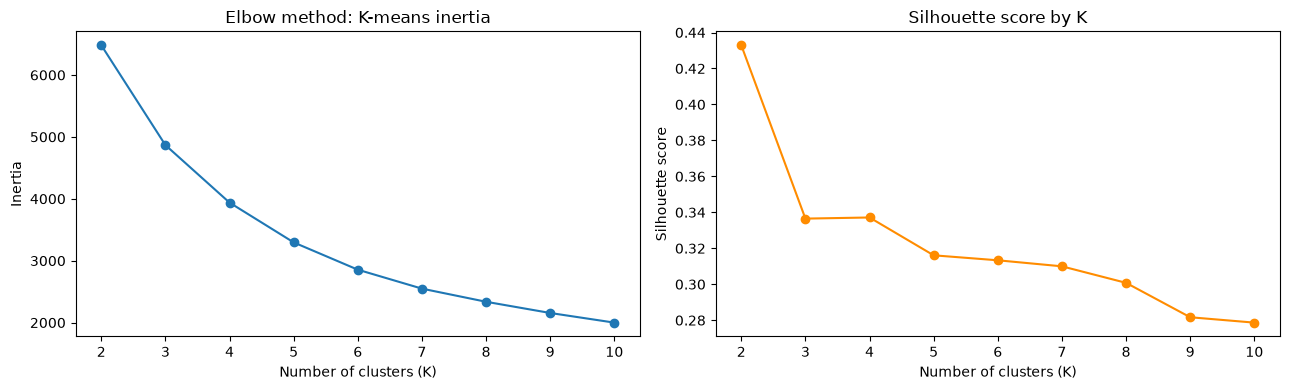

In [22]:
# Plot the elbow curve and silhouette scores side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(k_results_df.index, k_results_df["Inertia"], marker="o")
axes[0].set(title="Elbow method: K-means inertia", xlabel="Number of clusters (K)", ylabel="Inertia")

axes[1].plot(k_results_df.index, k_results_df["Silhouette"], marker="o", color="darkorange")
axes[1].set(title="Silhouette score by K", xlabel="Number of clusters (K)", ylabel="Silhouette score")

for ax in axes:
    ax.set_xticks(list(k_values))

plt.tight_layout()
save_fig("elbow_silhouette")
plt.show()

### Selected K = 4

- **K = 2 has the highest silhouette (0.433)**, but two clusters only separate recent, frequent buyers from lapsed ones. That is too coarse for targeted marketing.
- **Elbow:** inertia drops by about 25% from K = 2 to 3 and 19% from 3 to 4, then each extra cluster removes less (16%, 13%, 11%, ...). The bend is around K = 3 to 4.
- **Silhouette at K = 3 and K = 4 is essentially tied (0.337)** and declines steadily after K = 4.
- K = 4 gives one more segment than K = 3 at no real cost in separation, and every cluster still has 700+ customers, so no segment is too small to act on.
- **Limitation:** silhouette scores around 0.34 mean the segments overlap moderately. Customer RFM behaviour is closer to a continuum than to sharply separated groups.

In [23]:
# Number of clusters used for the final K-means model and agglomerative comparison
chosen_k = 4
k_results_df.loc[[chosen_k]].round(3)

,Inertia,Silhouette,SmallestCluster,InertiaDropPct
K,,,,
4,3938.51,0.337,716,19.091


## Final K-means model

We train K-means with the selected K = 4 on the scaled log-RFM features and assign a cluster label to each customer.

In [24]:
# Train the final K-means model with the selected number of clusters
final_kmeans = KMeans(n_clusters=chosen_k, n_init=10, random_state=42)
kmeans_labels = final_kmeans.fit_predict(rfm_scaled)

print("Inertia:", round(final_kmeans.inertia_, 3))
print("Silhouette score:", round(silhouette_score(rfm_scaled, kmeans_labels), 3))

Inertia: 3938.51
Silhouette score: 0.337


In [25]:
# Assign each customer its K-means cluster label
rfm_df["KMeansCluster"] = kmeans_labels
rfm_df.head()

,CustomerID,Recency,Frequency,Monetary,KMeansCluster
0,12346.0,326,1,77183.60,2
1,12347.0,2,7,4310.00,1
2,12348.0,75,4,1797.24,2
3,12349.0,19,1,1757.55,0
4,12350.0,310,1,334.40,3


### Stability check

K-means starts from random centers, so we refit it with ten different seeds and compare each result with the final model using the Adjusted Rand Index (1 = same clusters, 0 = no better than chance).

In [26]:
# Refit K-means with different random seeds and compare each result with the final model
from sklearn.metrics import adjusted_rand_score

seed_ari = pd.Series(
    {
        seed: adjusted_rand_score(
            kmeans_labels,
            KMeans(n_clusters=chosen_k, n_init=10, random_state=seed).fit_predict(rfm_scaled),
        )
        for seed in range(10)
    },
    name="ARI vs final model",
)
seed_ari.index.name = "Seed"

print(f"ARI across 10 seeds: min {seed_ari.min():.3f}, mean {seed_ari.mean():.3f}, max {seed_ari.max():.3f}")
seed_ari.round(3).to_frame().T

ARI across 10 seeds: min 0.942, mean 0.973, max 0.989


Seed,0,1,2,3,4,5,6,7,8,9
ARI vs final model,0.985,0.963,0.969,0.966,0.987,0.969,0.989,0.984,0.942,0.976


The ARI is between 0.94 and 0.99 for every seed, so the clusters don't depend on the random start.

## Analyze and visualize K-means clusters

For the fitted K-means model we report:

- **Cluster sizes:** how many customers fall in each segment
- **Median RFM statistics:** typical recency, frequency, and monetary value in each cluster
- **2D PCA plot:** scaled RFM features projected to two dimensions

In [27]:
# Cluster sizes and share of customers
kmeans_sizes = (
    rfm_df["KMeansCluster"]
    .value_counts()
    .sort_index()
    .rename("Customers")
    .to_frame()
)
kmeans_sizes["SharePct"] = kmeans_sizes["Customers"] / kmeans_sizes["Customers"].sum() * 100
kmeans_sizes.round(1)

,Customers,SharePct
KMeansCluster,,
0,837,19.3
1,716,16.5
2,1173,27.0
3,1612,37.2


In [28]:
# Median RFM statistics on the original (unscaled) features
kmeans_medians = (
    rfm_df.groupby("KMeansCluster")[["Recency", "Frequency", "Monetary"]]
    .median()
    .round(2)
)
kmeans_medians

,Recency,Frequency,Monetary
KMeansCluster,,,
0,17.0,2.0,471.70
1,8.0,10.0,3733.87
2,56.0,4.0,1345.62
3,177.0,1.0,298.26


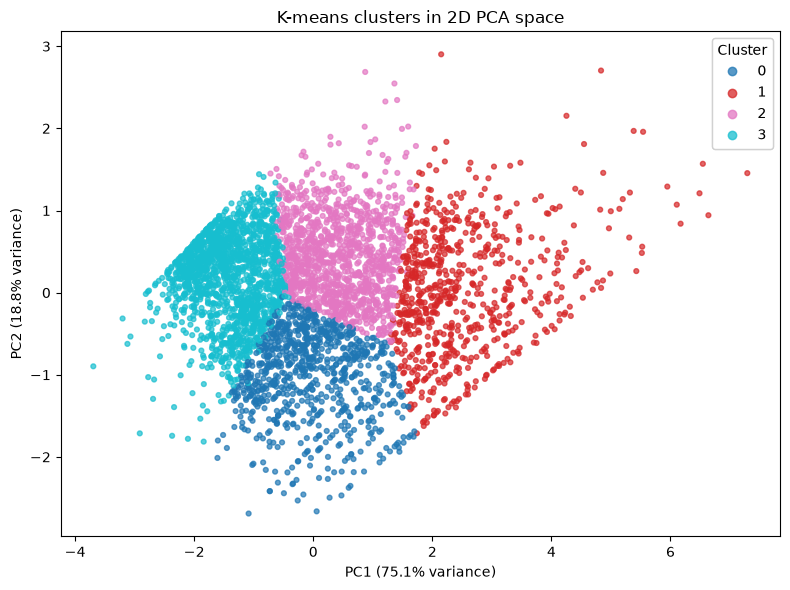

Variance explained by 2 PCs: 0.939


,Recency,Frequency,Monetary
PC1,-0.512,0.618,0.597
PC2,0.850,0.262,0.457


In [29]:
# 2D PCA of scaled RFM features, colored by K-means cluster
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
rfm_pca = pca.fit_transform(rfm_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    rfm_pca[:, 0],
    rfm_pca[:, 1],
    c=rfm_df["KMeansCluster"],
    cmap="tab10",
    s=12,
    alpha=0.7,
)
ax.set(
    title="K-means clusters in 2D PCA space",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)",
)
legend = ax.legend(*scatter.legend_elements(), title="Cluster")
ax.add_artist(legend)
plt.tight_layout()
save_fig("kmeans_pca")
plt.show()

print("Variance explained by 2 PCs:", pca.explained_variance_ratio_.sum().round(3))

# Loadings: how much each scaled RFM feature contributes to each principal component
pca_loadings = pd.DataFrame(pca.components_, columns=rfm_scaled.columns, index=["PC1", "PC2"])
pca_loadings.round(3)

The first two components keep about 94% of the variance, so the 2D plot is a good picture of the data. PC1 goes up with Frequency and Monetary and down with Recency, so customers further right are more valuable. PC2 is mostly Recency. The clusters sit next to each other along PC1 without clear gaps, which fits the moderate silhouette score.

## Train Agglomerative Clustering

We fit agglomerative (hierarchical) clustering on the **same scaled log-RFM features** and the **same number of clusters** (`chosen_k = 4`) so it is comparable with K-means. Ward linkage is used because, like K-means, it groups customers by minimizing within-cluster variance.

In [30]:
# Agglomerative clustering on the same scaled RFM features and same K
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=chosen_k, linkage="ward")
rfm_df["AggCluster"] = agg.fit_predict(rfm_scaled)

print("Agglomerative labels assigned to", len(rfm_df), "customers")
rfm_df.head()

Agglomerative labels assigned to 4338 customers


,CustomerID,Recency,Frequency,Monetary,KMeansCluster,AggCluster
0,12346.0,326,1,77183.60,2,0
1,12347.0,2,7,4310.00,1,1
2,12348.0,75,4,1797.24,2,0
3,12349.0,19,1,1757.55,0,1
4,12350.0,310,1,334.40,3,3


In [31]:
# Agglomerative cluster sizes
agg_sizes = (
    rfm_df["AggCluster"]
    .value_counts()
    .sort_index()
    .rename("Customers")
    .to_frame()
)
agg_sizes["SharePct"] = agg_sizes["Customers"] / agg_sizes["Customers"].sum() * 100
agg_sizes.round(1)

,Customers,SharePct
AggCluster,,
0,1820,42.0
1,1364,31.4
2,242,5.6
3,912,21.0


### Dendrogram

The dendrogram shows the order in which Ward linkage merges groups. The full tree has 4,338 leaves, so we only show the last 30 merges. The dashed line is where the tree is cut to get 4 clusters.

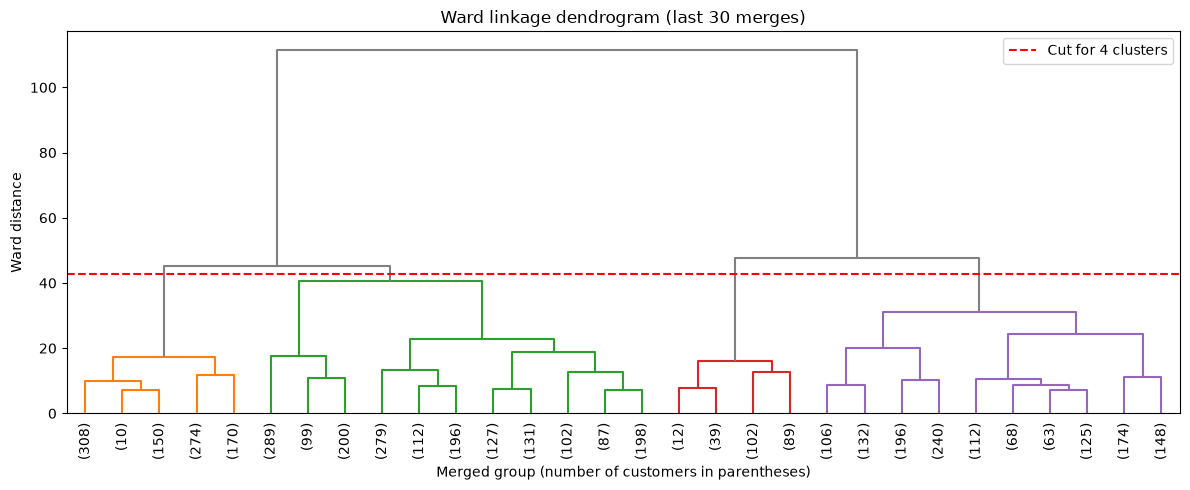

Agreement with AgglomerativeClustering labels (ARI): 1.0
Heights of the last five merges: [ 31.2  40.5  45.2  47.6 111.6]


In [32]:
# Dendrogram of the same Ward hierarchy, showing only the last 30 merges
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

ward_linkage = linkage(rfm_scaled.values, method="ward")

# Height halfway between the merges that leave 4 clusters and 3 clusters
cut_height = (ward_linkage[-chosen_k, 2] + ward_linkage[-(chosen_k - 1), 2]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(
    ward_linkage,
    truncate_mode="lastp",
    p=30,
    color_threshold=cut_height,
    above_threshold_color="gray",
    show_leaf_counts=True,
    leaf_rotation=90,
    ax=ax,
)
ax.axhline(cut_height, color="red", linestyle="--", label=f"Cut for {chosen_k} clusters")
ax.set(
    title="Ward linkage dendrogram (last 30 merges)",
    xlabel="Merged group (number of customers in parentheses)",
    ylabel="Ward distance",
)
ax.legend()
plt.tight_layout()
save_fig("dendrogram")
plt.show()

# Cutting this tree into 4 clusters reproduces the AgglomerativeClustering labels
tree_labels = fcluster(ward_linkage, t=chosen_k, criterion="maxclust")
print("Agreement with AgglomerativeClustering labels (ARI):", round(adjusted_rand_score(rfm_df["AggCluster"], tree_labels), 3))
print("Heights of the last five merges:", ward_linkage[-5:, 2].round(1))

The last merge is much taller than the rest, so the clearest split is into two groups, which matches K = 2 having the best silhouette score. Below that the merge heights are close together, so the tree does not point to one obvious number of clusters. We cut at 4 to match K-means.

## Compare both clustering methods

Feedback on our abstract suggested checking whether a second clustering method finds the same segments as K-means. Both models use the same scaled features and the same K. We compare silhouette scores, the Adjusted Rand Index, cluster sizes, median RFM values, and a crosstab of the two sets of labels.

In [33]:
agg_labels = rfm_df["AggCluster"]
sil_kmeans = silhouette_score(rfm_scaled, rfm_df["KMeansCluster"])
sil_agg = silhouette_score(rfm_scaled, agg_labels)
ari = adjusted_rand_score(rfm_df["KMeansCluster"], agg_labels)

print(f"K-means silhouette:        {sil_kmeans:.3f}")
print(f"Agglomerative silhouette:  {sil_agg:.3f}")
print(f"Adjusted Rand Index:       {ari:.3f}")

method_comparison = pd.DataFrame(
    {
        "Silhouette": [sil_kmeans, sil_agg],
        "SmallestCluster": [kmeans_sizes["Customers"].min(), agg_sizes["Customers"].min()],
        "LargestCluster": [kmeans_sizes["Customers"].max(), agg_sizes["Customers"].max()],
    },
    index=["K-means", "Agglomerative (Ward)"],
)
method_comparison.round(3)

K-means silhouette:        0.337
Agglomerative silhouette:  0.242
Adjusted Rand Index:       0.248


,Silhouette,SmallestCluster,LargestCluster
K-means,0.337,716,1612
Agglomerative (Ward),0.242,242,1820


In [34]:
size_comparison = pd.concat(
    [kmeans_sizes.add_prefix("KMeans_"), agg_sizes.add_prefix("Agg_")],
    axis=1,
)
size_comparison.round(1)

,KMeans_Customers,KMeans_SharePct,Agg_Customers,Agg_SharePct
0,837,19.3,1820,42.0
1,716,16.5,1364,31.4
2,1173,27.0,242,5.6
3,1612,37.2,912,21.0


In [35]:
agg_medians = (
    rfm_df.groupby("AggCluster")[["Recency", "Frequency", "Monetary"]]
    .median()
    .round(2)
)

print("K-means medians")
display(kmeans_medians)
print("Agglomerative medians")
display(agg_medians)

K-means medians


,Recency,Frequency,Monetary
KMeansCluster,,,
0,17.0,2.0,471.70
1,8.0,10.0,3733.87
2,56.0,4.0,1345.62
3,177.0,1.0,298.26


Agglomerative medians


,Recency,Frequency,Monetary
AggCluster,,,
0,64.0,2.0,529.95
1,17.0,5.0,1720.85
2,7.0,18.0,7507.88
3,245.5,1.0,230.82


In [36]:
# The cluster numbers are arbitrary
# K-Means cluster 0 is not exactly the same as Agglomerative cluster 0
# This will show what K-Means customers will be in what agglomerative cluster.
overlap = pd.crosstab(
    rfm_df["KMeansCluster"], rfm_df["AggCluster"],
    rownames=["KMeans"], colnames=["Agg"],
)
display(overlap)

# Same table as row percentages
display((overlap.div(overlap.sum(axis=1), axis=0) * 100).round(1))

Agg,0,1,2,3
KMeans,,,,
0,523,314,0,0
1,0,474,242,0
2,589,576,0,8
3,708,0,0,904


Agg,0,1,2,3
KMeans,,,,
0,62.5,37.5,0.0,0.0
1,0.0,66.2,33.8,0.0
2,50.2,49.1,0.0,0.7
3,43.9,0.0,0.0,56.1


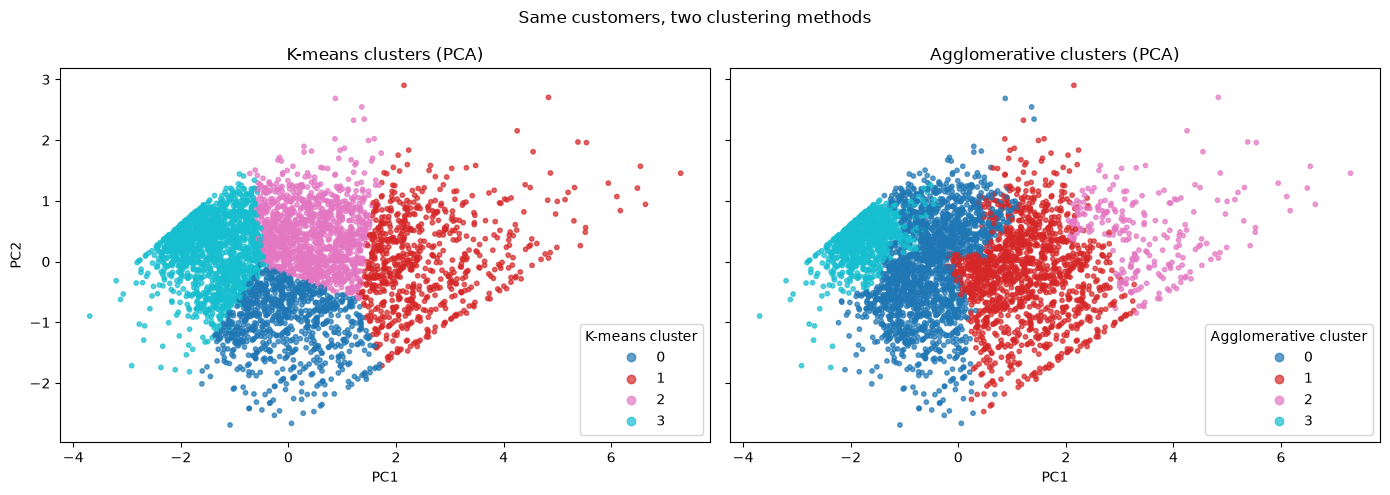

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, col, title in zip(
    axes, ["KMeansCluster", "AggCluster"], ["K-means", "Agglomerative"]
):
    scatter = ax.scatter(rfm_pca[:, 0], rfm_pca[:, 1], c=rfm_df[col], cmap="tab10", s=10, alpha=0.7)
    ax.set(title=f"{title} clusters (PCA)", xlabel="PC1")
    ax.legend(*scatter.legend_elements(), title=f"{title} cluster", loc="lower right")
axes[0].set_ylabel("PC2")

# Cluster numbers are arbitrary, so the same color does not mean the same group in both panels
fig.suptitle("Same customers, two clustering methods")
plt.tight_layout()
save_fig("kmeans_vs_agglomerative_pca")
plt.show()

### What the comparison shows

The two methods only partly agree (ARI of 0.25).

- They agree on the extremes. The smallest agglomerative cluster (242 customers, median 18 orders) is completely inside the K-means cluster with the best customers, and almost all of the agglomerative cluster with the longest recency (904 of 912) is inside the K-means cluster of inactive customers.
- They disagree in the middle. Agglomerative puts 1,820 customers into one big cluster that K-means splits across three of its clusters.
- K-means agreed with itself at 0.94 or higher across seeds, so the difference comes from the method and not from randomness.

We think this happens because the customers form a continuum instead of separate clumps, so there is no single correct place to draw the boundaries. Ward linkage also cannot undo a merge once it is made, while K-means keeps reassigning points.

We use K-means for the final segments because it has the higher silhouette score (0.337 vs 0.242) and more even cluster sizes.

## Baseline: traditional RFM quintile scoring

Before clustering, the usual way to segment customers with RFM is to score each customer 1 to 5 on each feature by quintile (Hughes, 1994). We use that as a baseline:

- Recency is reversed, so the most recent 20% of customers score 5.
- Frequency is ranked first, because about a third of customers have exactly one order and identical values cannot be split into quintiles.
- The three scores are kept as cells (for example 5-5-5) or summed into a total from 3 to 15. We cut the total into four tiers (3-5, 6-8, 9-11, 12-15) so the baseline has the same number of groups as K-means.

We score both versions with the same silhouette measure on the same scaled log-RFM features, and compare the tiers with K-means using ARI and a crosstab.

In [38]:
# Classic RFM quintile scores (1 = worst, 5 = best)
rfm_df["R_score"] = pd.qcut(rfm_df["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_df["F_score"] = pd.qcut(rfm_df["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_df["M_score"] = pd.qcut(rfm_df["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Version 1: every R-F-M combination is its own cell
rfm_cell = rfm_df[["R_score", "F_score", "M_score"]].astype(str).agg("".join, axis=1)
cell_counts = rfm_cell.value_counts()
print("Occupied RFM cells:", len(cell_counts), "| cells with fewer than 10 customers:", (cell_counts < 10).sum())

# Version 2: sum the scores and cut into four tiers
rfm_score = rfm_df[["R_score", "F_score", "M_score"]].sum(axis=1)
rfm_df["RFMTier"] = pd.cut(
    rfm_score, bins=[2, 5, 8, 11, 15],
    labels=["Low (3-5)", "Mid-low (6-8)", "Mid-high (9-11)", "Top (12-15)"],
)
tier_codes = rfm_df["RFMTier"].cat.codes

baseline_comparison = pd.DataFrame(
    {
        "Groups": [len(cell_counts), 4, chosen_k, chosen_k],
        "Silhouette": [
            silhouette_score(rfm_scaled, rfm_cell),
            silhouette_score(rfm_scaled, tier_codes),
            silhouette_score(rfm_scaled, rfm_df["AggCluster"]),
            silhouette_score(rfm_scaled, rfm_df["KMeansCluster"]),
        ],
        "ARI vs K-means": [
            np.nan,
            adjusted_rand_score(rfm_df["KMeansCluster"], tier_codes),
            adjusted_rand_score(rfm_df["KMeansCluster"], rfm_df["AggCluster"]),
            1.0,
        ],
    },
    index=["RFM quintile cells", "RFM score tiers", "Agglomerative (Ward)", "K-means"],
)
display(baseline_comparison.round(3))

# Size, revenue share, and median RFM of each tier
tier_summary = rfm_df.groupby("RFMTier", observed=True).agg(
    Customers=("CustomerID", "count"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Revenue=("Monetary", "sum"),
)
tier_summary["CustomerPct"] = tier_summary["Customers"] / tier_summary["Customers"].sum() * 100
tier_summary["RevenuePct"] = tier_summary["Revenue"] / tier_summary["Revenue"].sum() * 100
display(tier_summary.drop(columns="Revenue").iloc[::-1].round(1))

# Where the K-means clusters land in the baseline tiers (names match the segments below)
kmeans_names = {0: "Recent low spenders", 1: "Loyal high-value", 2: "Mid-value at risk", 3: "Inactive one-time"}
pd.crosstab(rfm_df["KMeansCluster"].map(kmeans_names), rfm_df["RFMTier"], rownames=["K-means"], colnames=["RFM tier"])

Occupied RFM cells: 118 | cells with fewer than 10 customers: 34


,Groups,Silhouette,ARI vs K-means
RFM quintile cells,118,0.023,NaN
RFM score tiers,4,0.196,0.362
Agglomerative (Ward),4,0.242,0.248
K-means,4,0.337,1.000


,Customers,Recency,Frequency,Monetary,CustomerPct,RevenuePct
RFMTier,,,,,,
Top (12-15),1255,12.0,7.0,2552.2,28.9,76.7
Mid-high (9-11),1022,40.0,3.0,835.4,23.6,13.4
Mid-low (6-8),1178,74.0,1.0,401.0,27.2,7.7
Low (3-5),883,239.0,1.0,200.2,20.4,2.3


RFM tier,Low (3-5),Mid-low (6-8),Mid-high (9-11),Top (12-15)
K-means,,,,
Inactive one-time,882,720,10,0
Loyal high-value,0,0,1,715
Mid-value at risk,0,144,622,407
Recent low spenders,1,314,389,133


### What the baseline shows

- Quintile cells are too fine to use. 118 of the 125 possible cells are occupied, 34 of them by fewer than 10 customers, and the cells barely separate customers (silhouette 0.023).
- Four score tiers are usable, but K-means separates customers better (silhouette 0.337 vs 0.196, and an ARI of 0.36 between the two).
- The top tier holds 715 of the 716 loyal high-value customers, but also 407 mid-value at-risk customers and 133 recent low spenders. Summing the scores lets high Frequency and Monetary make up for poor Recency, so a regular buyer who has gone quiet scores the same as an active one. K-means keeps those customers in their own at-risk segment, which is the group the win-back recommendations target.
- Silhouette is measured in the same space K-means optimizes, so it favours K-means. Who ends up in each group is the stronger evidence.

## Interpret customer segments

We name each K-means cluster from its median RFM profile. K-means is used for the final segments because it had the higher silhouette score and more balanced cluster sizes than agglomerative clustering.

In [39]:
# Segment names based on the K-means median RFM profiles
segment_names = {
    0: "Recent low spenders",
    1: "Loyal high-value",
    2: "Mid-value at risk",
    3: "Inactive one-time",
}
rfm_df["Segment"] = rfm_df["KMeansCluster"].map(segment_names)

segment_summary = rfm_df.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Revenue=("Monetary", "sum"),
)
segment_summary["CustomerPct"] = segment_summary["Customers"] / segment_summary["Customers"].sum() * 100
segment_summary["RevenuePct"] = segment_summary["Revenue"] / segment_summary["Revenue"].sum() * 100
segment_summary = segment_summary.drop(columns="Revenue").sort_values("Monetary", ascending=False)
segment_summary.round(1)

,Customers,Recency,Frequency,Monetary,CustomerPct,RevenuePct
Segment,,,,,,
Loyal high-value,716,8.0,10.0,3733.9,16.5,64.9
Mid-value at risk,1173,56.0,4.0,1345.6,27.0,23.7
Recent low spenders,837,17.0,2.0,471.7,19.3,5.2
Inactive one-time,1612,177.0,1.0,298.3,37.2,6.2


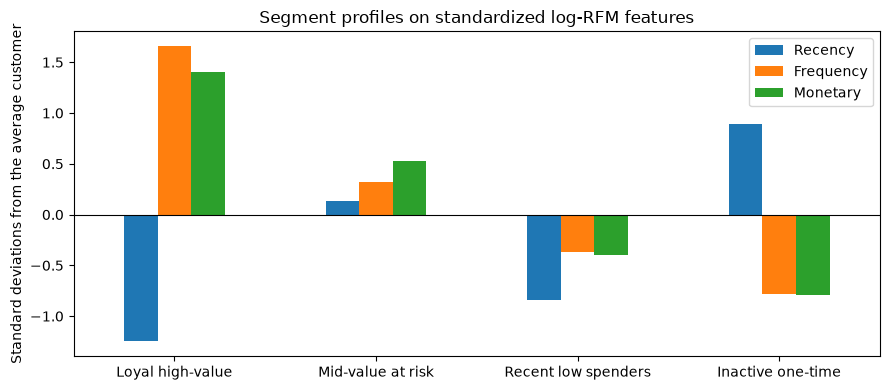

In [40]:
# Average standardized log-RFM value of each segment (0 = the average customer)
segment_order = ["Loyal high-value", "Mid-value at risk", "Recent low spenders", "Inactive one-time"]
segment_profile = rfm_scaled.groupby(rfm_df["Segment"]).mean().loc[segment_order]

ax = segment_profile.plot.bar(figsize=(9, 4), rot=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    title="Segment profiles on standardized log-RFM features",
    xlabel="",
    ylabel="Standard deviations from the average customer",
)
plt.tight_layout()
save_fig("segment_profiles")
plt.show()

### Segment profiles

- **Loyal high-value (16.5% of customers, 64.9% of revenue):** bought within the last ~8 days, about 10 orders, median spend around 3,700. The most valuable group by far.
- **Mid-value at risk (27.0%, 23.7% of revenue):** regular buyers (about 4 orders, ~1,350 spend) who have not purchased in roughly two months. Worth re-engaging before they lapse.
- **Recent low spenders (19.3%, 5.2% of revenue):** purchased recently but only once or twice with small baskets. Mostly newer customers who could grow into repeat buyers.
- **Inactive one-time (37.2%, 6.2% of revenue):** a single small order about six months ago. The largest group but contributes little revenue.

In the chart above, low Recency is good and high Frequency and Monetary are good.

Agglomerative clustering agrees with these segments at the top and bottom but splits the middle differently (see the comparison above), so customers near a boundary could reasonably belong to either neighbouring segment.

## Develop marketing recommendations

We turn the four K-means segments into marketing actions. Before writing recommendations, we look at a few extra behaviours for each segment that the RFM medians do not show directly:

- **Order habits:** typical order value, items per order, and the usual number of days between a customer's orders
- **Timing:** how recently each segment bought, and how much of its spending came in the September to November holiday ramp
- **Products:** the items bought by the most customers in each segment, to use in targeted offers

In [41]:
# Attach each customer's segment to the cleaned transactions
segment_tx = cleaned_df.merge(rfm_df[["CustomerID", "Segment"]], on="CustomerID")

# One row per purchase invoice
invoices = segment_tx.groupby(["Segment", "CustomerID", "InvoiceNo"]).agg(
    OrderValue=("TotalPrice", "sum"),
    Items=("StockCode", "nunique"),
    InvoiceDate=("InvoiceDate", "min"),
).reset_index().sort_values("InvoiceDate")

# Days between consecutive orders from the same customer (repeat buyers only)
invoices["DaysSincePrevOrder"] = invoices.groupby("CustomerID")["InvoiceDate"].diff().dt.days

# Customer home country and share of each customer's spending in Sep-Nov
customer_country = segment_tx.groupby("CustomerID")["Country"].first()
holiday_spend = segment_tx[segment_tx["InvoiceDate"].dt.month.isin([9, 10, 11])].groupby("Segment")["TotalPrice"].sum()

segment_behaviour = pd.DataFrame({
    "Customers": rfm_df.groupby("Segment")["CustomerID"].count(),
    "RevenuePct": rfm_df.groupby("Segment")["Monetary"].sum() / rfm_df["Monetary"].sum() * 100,
    "MedianOrderValue": invoices.groupby("Segment")["OrderValue"].median(),
    "MedianItemsPerOrder": invoices.groupby("Segment")["Items"].median(),
    "MedianDaysBetweenOrders": invoices.groupby("Segment")["DaysSincePrevOrder"].median(),
    "OneOrderPct": rfm_df.groupby("Segment")["Frequency"].apply(lambda f: (f == 1).mean() * 100),
    "UKPct": rfm_df.assign(UK=rfm_df["CustomerID"].map(customer_country).eq("United Kingdom")).groupby("Segment")["UK"].mean() * 100,
    "SepNovSpendPct": holiday_spend / segment_tx.groupby("Segment")["TotalPrice"].sum() * 100,
}).sort_values("RevenuePct", ascending=False)

segment_behaviour.round(1)

,Customers,RevenuePct,MedianOrderValue,MedianItemsPerOrder,MedianDaysBetweenOrders,OneOrderPct,UKPct,SepNovSpendPct
Segment,,,,,,,,
Loyal high-value,716,64.9,321.5,15.0,14.0,0.0,88.7,34.8
Mid-value at risk,1173,23.7,308.1,16.0,48.0,2.8,88.4,33.6
Inactive one-time,1612,6.2,203.9,12.0,61.0,73.9,91.6,26.4
Recent low spenders,837,5.2,208.3,15.0,55.0,32.0,92.1,61.7


In [42]:
# How long since each segment's customers last bought (row percentages)
recency_bins = pd.cut(
    rfm_df["Recency"],
    bins=[0, 30, 60, 90, 180, 400],
    labels=["0-30 days", "31-60", "61-90", "91-180", "181+"],
)
recency_mix = pd.crosstab(rfm_df["Segment"], recency_bins, normalize="index") * 100
display(recency_mix.round(1))

# When each segment's customers made their first purchase
first_purchase = segment_tx.groupby("CustomerID")["InvoiceDate"].min().dt.to_period("Q")
first_quarter_mix = pd.crosstab(rfm_df["Segment"], rfm_df["CustomerID"].map(first_purchase).rename("FirstPurchaseQuarter"))
display(first_quarter_mix)

# Mid-value at risk: share of customers who have gone longer than their own usual gap between orders
usual_gap = invoices.groupby("CustomerID")["DaysSincePrevOrder"].median()
at_risk = rfm_df[rfm_df["Segment"] == "Mid-value at risk"].copy()
at_risk["UsualGap"] = at_risk["CustomerID"].map(usual_gap)
overdue_pct = (at_risk["Recency"] > at_risk["UsualGap"]).mean() * 100
print(f"Mid-value at risk customers past their usual reorder gap: {overdue_pct:.1f}%")
print(f"Mid-value at risk revenue: {at_risk['Monetary'].sum():,.0f} GBP")

Recency,0-30 days,31-60,61-90,91-180,181+
Segment,,,,,
Inactive one-time,0.2,11.8,15.8,23.4,48.7
Loyal high-value,92.9,6.1,0.8,0.0,0.1
Mid-value at risk,24.0,31.8,19.8,18.1,6.3
Recent low spenders,83.3,16.7,0.0,0.0,0.0


FirstPurchaseQuarter,2010Q4,2011Q1,2011Q2,2011Q3,2011Q4
Segment,,,,,
Inactive one-time,200,456,377,343,236
Loyal high-value,379,209,69,40,19
Mid-value at risk,235,485,274,139,40
Recent low spenders,71,99,106,134,427


Mid-value at risk customers past their usual reorder gap: 44.7%
Mid-value at risk revenue: 2,114,718 GBP


In [43]:
# Products bought by the most customers in each segment
# Non-product codes (postage, fees, manual adjustments) are excluded
non_product_codes = ["POST", "DOT", "M", "C2", "BANK CHARGES", "AMAZONFEE", "PADS", "CRUK"]
product_tx = segment_tx[~segment_tx["StockCode"].astype(str).isin(non_product_codes)]

top_products = (
    product_tx.groupby(["Segment", "Description"])["CustomerID"].nunique()
    .rename("Customers")
    .reset_index()
    .sort_values(["Segment", "Customers"], ascending=[True, False])
    .groupby("Segment")
    .head(5)
    .reset_index(drop=True)
)
top_products["PctOfSegment"] = top_products["Customers"] / top_products["Segment"].map(segment_behaviour["Customers"]) * 100
top_products.round(1)

,Segment,Description,Customers,PctOfSegment
0,Inactive one-time,WHITE HANGING HEART T-LIGHT HOLDER,198,12.3
1,Inactive one-time,REGENCY CAKESTAND 3 TIER,177,11.0
2,Inactive one-time,PARTY BUNTING,148,9.2
3,Inactive one-time,ASSORTED COLOUR BIRD ORNAMENT,130,8.1
4,Inactive one-time,SET OF 3 CAKE TINS PANTRY DESIGN,127,7.9
5,Loyal high-value,REGENCY CAKESTAND 3 TIER,262,36.6
6,Loyal high-value,WHITE HANGING HEART T-LIGHT HOLDER,253,35.3
7,Loyal high-value,JUMBO BAG RED RETROSPOT,252,35.2
8,Loyal high-value,LUNCH BAG RED RETROSPOT,246,34.4
9,Loyal high-value,PACK OF 72 RETROSPOT CAKE CASES,240,33.5


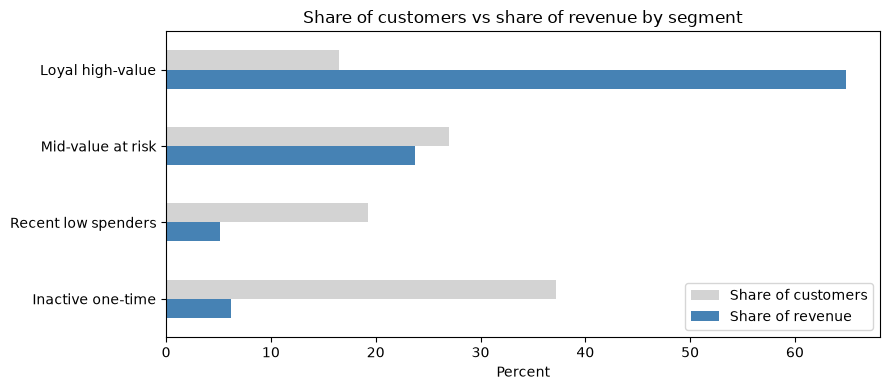

In [44]:
# Revenue share by segment, with each segment's recommended priority
priority_order = ["Loyal high-value", "Mid-value at risk", "Recent low spenders", "Inactive one-time"]
plot_data = segment_behaviour.loc[priority_order, ["Customers", "RevenuePct"]].copy()
plot_data["CustomerPct"] = plot_data["Customers"] / plot_data["Customers"].sum() * 100

ax = plot_data[["CustomerPct", "RevenuePct"]].plot.barh(figsize=(9, 4), color=["lightgray", "steelblue"])
ax.invert_yaxis()
ax.set(title="Share of customers vs share of revenue by segment", xlabel="Percent", ylabel="")
ax.legend(["Share of customers", "Share of revenue"])
plt.tight_layout()
save_fig("segment_revenue_share")
plt.show()

### Recommendations by segment

**1. Loyal high-value (16.5% of customers, 64.9% of revenue): retain and reward**

*Evidence:* these customers reorder about every two weeks, almost all bought in the last 30 days, and they carry nearly two thirds of revenue. Losing even a small number of them costs more than any other segment can add.

- **Loyalty / VIP tier:** early access to new seasonal ranges, priority stock allocation on best sellers, and free delivery above a threshold. Many of these customers buy in wholesale-sized baskets, so service perks are likely to matter more than small discounts.
- **Replenishment reminders:** since the typical gap is about 14 days, send a reorder reminder with their most-bought items when a customer passes roughly twice their usual gap, before they drift into the at-risk group.
- **Cross-sell, not discount:** recommend items frequently bought by other loyal customers (see the product table) instead of discounting items they already buy at full price.
- **Avoid over-contacting:** keep promotional volume low; this group is already buying.
- *KPI:* retention rate and order frequency for this segment; number of customers moving from loyal to at-risk each month.

**2. Mid-value at risk (27.0%, 23.7% of revenue): win back before they lapse**

*Evidence:* these customers normally reorder about every 48 days, but their median recency is 56 days, about 76% have not bought in the last 30 days, and about 45% are already past their own usual reorder gap. This segment holds about 2.1M GBP of revenue, the largest amount that can still realistically be saved.

- **Triggered win-back:** automatically contact a customer once they pass their own usual gap between orders (for example, around 60 days), instead of waiting for a fixed calendar campaign.
- **Time-limited incentive:** a modest discount or free shipping on the next order with a short expiry (for example, 14 days) to create urgency. Use bigger offers only for customers whose past spending justifies them.
- **Personalised content:** feature the products they bought before and close substitutes, since this group buys the same core items as the loyal segment (cake stands, T-light holders, cake cases).
- **Feedback request:** a short survey for customers who do not respond, to learn whether they switched supplier or simply had no need.
- *KPI:* reactivation rate (share who place another order within 30 days of contact) and revenue recovered per GBP of discount given.

**3. Recent low spenders (19.3%, 5.2% of revenue): convert to repeat buyers**

*Evidence:* most of these customers are new. About half (427 of 837) made their first purchase in the last quarter of 2011, about 62% of their spending came in September to November, and their most common products are seasonal items such as Christmas paper chain kits. Their orders are smaller (median order value about 210 GBP vs about 320 GBP for loyal customers) and about a third have ordered only once.

- **Onboarding sequence:** a welcome series after the first order that introduces the wider range, best sellers, and how to reorder.
- **Second-order incentive:** an offer valid on the next order within 30-45 days. The second order is the step that most often separates a one-time buyer from a repeat customer.
- **Grow basket size:** free shipping or a small discount once an order passes a threshold set slightly above their current typical order value, plus product bundles of commonly bought-together items.
- **Post-holiday follow-up:** because much of this group was acquired during the holiday ramp, plan a January to February campaign so they do not become next year's inactive one-time customers.
- *KPI:* second-purchase rate within 60 days, average order value, and share of this segment that moves into the at-risk or loyal segments.

**4. Inactive one-time (37.2%, 6.2% of revenue): low-cost reactivation**

*Evidence:* the largest segment but the smallest revenue per customer. About 74% have placed only one order, and about half have not bought in more than six months.

- **Low-cost channels only:** automated email rather than paid advertising or sales calls, because expected revenue per customer is low.
- **Split by recency:** customers who lapsed within the last ~90 days get a "we miss you" offer; customers inactive for 6+ months get one final reactivation message before being moved to a lower-frequency mailing list.
- **Seasonal hook:** time reactivation emails before the September to November peak featuring the home decor and party items this segment bought most (T-light holders, cake stands, party bunting).
- **List hygiene:** stop sending to contacts who do not engage after the reactivation attempt, which lowers cost and protects email deliverability for the other segments.
- *KPI:* reactivation rate and cost per reactivated customer; unsubscribe and bounce rates.

### Overall priorities

| Priority | Segment | Goal | Main action | Spend level |
|---|---|---|---|---|
| 1 | Loyal high-value | Retain | Loyalty tier, replenishment reminders, cross-sell | Medium (service perks, not discounts) |
| 2 | Mid-value at risk | Win back | Triggered win-back with time-limited incentive | Medium to high |
| 3 | Recent low spenders | Develop | Onboarding and second-order incentive, basket-size thresholds | Medium |
| 4 | Inactive one-time | Reactivate cheaply | Automated email, then reduce contact | Low |

**Cross-segment recommendations**

- **Plan around the seasonal peak:** monthly sales roughly double from summer to November, so loyalty offers, new product launches, and reactivation campaigns should be ready by late August.
- **Focus on the UK first:** about 88-92% of customers in every segment are UK-based, so UK campaigns reach most of each segment. Non-UK customers are few but some (for example the Netherlands and EIRE) spend heavily per customer, so they may suit account-style follow-up.
- **Re-score customers regularly:** recompute RFM features and segment assignments monthly so customers are moved between campaigns as their behaviour changes (for example, a recent low spender who places a third order should leave the second-order campaign).
- **Test before scaling:** run each campaign with a randomly held-out control group so the effect of the campaign can be measured against customers who were not contacted.

### Limitations of these recommendations

- The data has no product cost, margin, or marketing cost information, so the recommended incentive levels are directional and should be checked against margins before use.
- There is no record of past campaigns or customer responses, so expected response rates are unknown until the campaigns are tested.
- The dataset covers about one year and appears to include many wholesale customers, so behaviour may differ from a typical consumer retailer.
- As noted when choosing K, the segments overlap moderately (silhouette about 0.34). Customers near segment boundaries may fit more than one campaign, which is another reason to re-score them regularly.

## Limitations

- About 25% of the raw rows had no CustomerID and were dropped, so those buyers are not in any segment.
- Monetary is gross spending. We removed cancellations but did not subtract them from the original orders.
- We only use three features. RFM says nothing about what customers buy.
- The data covers one year and Recency is measured right after the holiday peak, so customers who first bought in autumn look like recent low spenders partly because they have not had time to reorder.
- The clusters overlap (silhouette 0.34) and the two methods agree only weakly, so the segments are a useful way to split a continuum and not sharply separate groups.
- There are no labels or campaign results to check the segments against.

## Conclusion

After cleaning we had 397,884 purchase rows from 4,338 customers. K-means with K = 4 on log-scaled RFM features gave four segments: loyal high-value customers (16.5% of customers, 64.9% of revenue), mid-value customers at risk of leaving (27.0%, 23.7%), recent low spenders (19.3%, 5.2%), and inactive one-time buyers (37.2%, 6.2%). The result was stable across random seeds. Agglomerative clustering found the same top and bottom groups but split the middle differently, so we treat the middle boundaries as approximate.

With more time we would use net revenue after returns, add features about what customers buy, and try a Gaussian mixture model since it gives probabilities instead of hard cluster labels.

## References

1. Chen, D. (2015). Online Retail [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
2. Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. Journal of Database Marketing & Customer Strategy Management, 19(3), 197-208.
3. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825-2830.
4. Virtanen, P., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17, 261-272.
5. Hughes, A. M. (1994). Strategic Database Marketing. Probus Publishing.